# Lab 05 · Predict late deliveries

QuickBite can offer a $4 voucher when an order is placed. A late order that was **not** flagged costs $15.
This notebook explains the decisions behind `python -m latedeliveries.train`.

Every number here comes from the **training data** (cross-validation), except section 7, which reads the
test-set result that `train.py` saved after scoring the test set **once**. The notebook never scores the test set itself.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate

from latedeliveries.data import make_orders
from latedeliveries.evaluation import choose_threshold, cost_by_threshold
from latedeliveries.pipeline import (
    CATEGORICAL,
    NUMERIC,
    RUSH_HOURS,
    SEED,
    build_pipeline,
    load_split,
)

# The notebook lives in notebooks/, the reports and models one folder up.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

## 1. How common are late orders?

In [2]:
orders = make_orders()
print(f"Orders: {len(orders)}")
print(f"Late rate: {orders['late'].mean():.1%}")
print()
print("Missing values per column:")
print(orders.isna().sum()[orders.isna().sum() > 0])

Orders: 3000
Late rate: 15.6%

Missing values per column:
prep_minutes        189
customer_rating    1489
dtype: int64


About one order in six is late, so a model that always says "on time" is right about 84% of the time.
That is why accuracy is not the measure we choose by.

## 2. Which orders arrive late? (business view, training data only)

Before any model, a manager's question: does lateness depend on distance, order size and the time of day?
Distance and order size are put into three segments here only to **read** the data.

In [3]:
X_train, X_test, y_train, y_test = load_split()
train = X_train.assign(late=y_train)

segments = pd.DataFrame(
    {
        "distance": pd.cut(
            train["distance_km"], [0, 2, 5, 99], labels=["0-2 km", "2-5 km", "5+ km"]
        ),
        "order size": pd.cut(
            train["items"],
            [0, 2, 5, 99],
            labels=["1-2 items", "3-5 items", "6-8 items"],
        ),
        "time of day": train["hour"]
        .isin(RUSH_HOURS)
        .map({True: "rush", False: "normal"}),
        "day": train["day_type"],
        "weather": train["weather"],
    }
)
for column in segments:
    table = train.groupby(segments[column], observed=True)["late"].agg(["mean", "size"])
    table.columns = ["late rate", "orders"]
    print(table.round(3), end="\n\n")

          late rate  orders
distance                   
0-2 km        0.053     624
2-5 km        0.113    1026
5+ km         0.337     600

            late rate  orders
order size                   
1-2 items       0.114     546
3-5 items       0.155     838
6-8 items       0.184     866

             late rate  orders
time of day                   
normal           0.113    1431
rush             0.232     819

         late rate  orders
day                       
weekday      0.134    1497
weekend      0.201     753

         late rate  orders
weather                   
clear        0.124    1616
rain         0.224     504
snow         0.292     130



All three business intuitions hold: far orders are late about six times as often as near ones, large orders
more often than small ones, and rush-hour orders about twice as often as the rest.

## 3. Which columns may the model use?

A column is a legitimate feature only if its value is **known when the order is placed**.
`customer_rating` is given after delivery, so it is excluded. The table shows why it would be tempting:

In [4]:
rated = train.dropna(subset=["customer_rating"])
print(f"Share of orders with a rating: {train['customer_rating'].notna().mean():.0%}")
print(rated.groupby("customer_rating")["late"].mean().round(2).rename("late rate"))

Share of orders with a rating: 51%
customer_rating
2.0    1.00
3.0    0.83
4.0    0.09
5.0    0.00
Name: late rate, dtype: float64


Low ratings almost always mean a late order, because the customer rated **after** the delay happened.
The model would learn to read the outcome from its own consequence. Also excluded: `order_id`
(a label with no meaning) and `hour` (replaced by `rush`, see section 4).

## 4. Feature experiments: hour, rush and segments

In [5]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
base_numeric = ["distance_km", "items", "prep_minutes", "courier_months"]
base_categorical = ["weather", "day_type", "vehicle"]


DISTANCE_BANDS = ["near", "mid", "far"]
SIZE_BANDS = ["small", "medium", "large"]
SEGMENTS = ["distance_band", "size_band"]


def with_segments(X):
    # Three distance and three size segments, computed per row from the order itself.
    return X.assign(
        distance_band=pd.cut(X["distance_km"], [0, 2, 5, 99], labels=DISTANCE_BANDS),
        size_band=pd.cut(X["items"], [0, 2, 5, 99], labels=SIZE_BANDS),
    )


variants = {
    "1 hour as a number": (base_numeric + ["hour"], base_categorical),
    "2 hour as a category": (base_numeric, base_categorical + ["hour"]),
    "3 rush only (chosen)": (NUMERIC, CATEGORICAL),
    "4 rush + hour as a number": (NUMERIC + ["hour"], CATEGORICAL),
    "5 rush + hour as a category": (NUMERIC, CATEGORICAL + ["hour"]),
    "6 rush + distance and size segments": (NUMERIC, CATEGORICAL + SEGMENTS),
    "7 segments replace raw distance and items": (
        ["prep_minutes", "courier_months"],
        CATEGORICAL + SEGMENTS,
    ),
    "LEAK: chosen + customer_rating": (NUMERIC + ["customer_rating"], CATEGORICAL),
}
# The bands become plain text, so the encoder treats them as categories.
X_exp = with_segments(X_train).astype({"distance_band": str, "size_band": str})
rows = []
for name, (numeric, categorical) in variants.items():
    pipe = build_pipeline(LogisticRegression(max_iter=1000), numeric, categorical)
    scores = cross_validate(pipe, X_exp, y_train, cv=folds, scoring=["roc_auc", "f1"])
    probabilities = cross_val_predict(
        pipe, X_exp, y_train, cv=folds, method="predict_proba"
    )[:, 1]
    best = choose_threshold(y_train, probabilities)
    rows.append(
        {
            "variant": name,
            "roc_auc": scores["test_roc_auc"].mean().round(3),
            "roc_auc_std": scores["test_roc_auc"].std().round(3),
            "lowest_cv_cost": cost_by_threshold(y_train, probabilities)[best],
        }
    )
experiments = pd.DataFrame(rows)
experiments.to_csv(ROOT / "reports" / "feature_experiments.csv", index=False)
experiments

,variant,roc_auc,roc_auc_std,lowest_cv_cost
0,1 hour as a number,0.795,0.034,4031
1,2 hour as a category,0.812,0.034,4096
2,3 rush only (chosen),0.816,0.034,4042
3,4 rush + hour as a number,0.815,0.035,4023
4,5 rush + hour as a category,0.812,0.034,4089
5,6 rush + distance and size segments,0.816,0.033,4032
6,7 segments replace raw distance and items,0.798,0.044,4220
7,LEAK: chosen + customer_rating,0.920,0.014,3035


**Hour.** As a single number, logistic regression can only learn "later is riskier" (or the reverse), so it
misses the lunch and dinner peaks (1, ROC-AUC 0.795). As a category it sees the peaks but has to learn
13 separate hours from a few hundred orders each (2, 0.812). Grouping hours into rush and normal, from
business knowledge, ranks orders best (3, 0.816) with fewer columns. Adding the raw hour back adds nothing (4, 5).

**Distance and size segments** add nothing on top of the raw numbers (6) and hurt when they replace them (7):
risk rises smoothly with distance and size, which the model already learns from the numbers, and banding
throws detail away. Grouping helps when the relationship has peaks, as hour does, not when it is a straight rise.

**Cost.** Variants 1, 3, 4 and 6 end within $20 of each other on 2,250 orders, which is noise; only 7 is clearly worse.

**Leakage.** Adding `customer_rating` lifts ROC-AUC from 0.816 to 0.920 and cuts the cost by about $1,000.
A jump that large from one column is a warning, not good news: that column is not available when the order is placed.

All differences except the leak are inside the fold-to-fold spread (about ±0.035), so they are signals, not proof.

## 5. Model comparison (5-fold cross-validation, training data)

In [6]:
comparison = pd.read_csv(ROOT / "reports" / "cv_results.csv")
columns = ["model", "accuracy_mean", "precision_mean", "recall_mean", "f1_mean"]
columns += ["roc_auc_mean", "roc_auc_std", "best_threshold", "lowest_cv_cost"]
comparison[columns]

,model,accuracy_mean,precision_mean,recall_mean,f1_mean,roc_auc_mean,roc_auc_std,best_threshold,lowest_cv_cost
0,dummy_baseline,0.844,0.000,0.000,0.000,0.500,0.000,0.05,5265
1,logreg,0.872,0.715,0.290,0.413,0.816,0.034,0.30,4042
2,logreg_balanced,0.752,0.355,0.724,0.476,0.816,0.035,0.70,4044
3,random_forest_balanced,0.782,0.376,0.598,0.461,0.795,0.037,0.60,4180


The baseline reaches 84% accuracy while catching no late order at all, so accuracy cannot pick the model.
The two logistic regressions reach the same lowest cost once each gets its own threshold; the random forest
costs more and ranks orders less well, because the effects in this data simply add up.

## 6. Choosing the threshold from costs

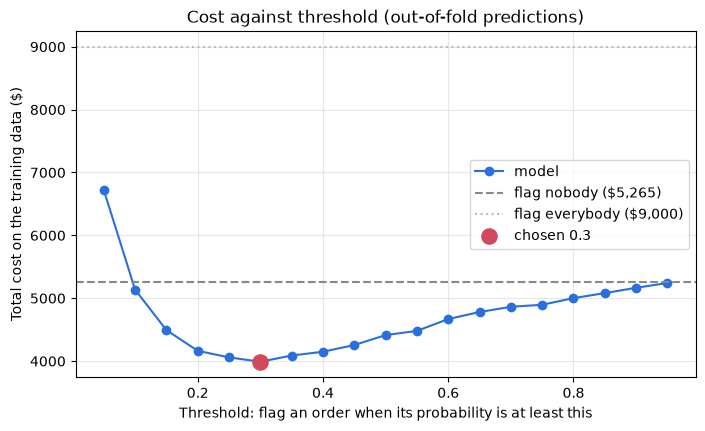

Tuning: {'scoring': 'roc_auc', 'best_params': {'model__C': '0.1', 'model__class_weight': 'None'}, 'best_cv_roc_auc': 0.817, 'best_cv_roc_auc_std': 0.032, 'untuned_cv_roc_auc': 0.816, 'untuned_cv_roc_auc_std': 0.035}


In [7]:
info = json.loads((ROOT / "models" / "model_info.json").read_text())
costs = {float(t): c for t, c in info["cv_cost_by_threshold"].items()}
chosen = info["threshold"]
n_train, n_late = len(y_train), int(y_train.sum())
nobody_cost, everybody_cost = 15 * n_late, 4 * n_train

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(list(costs), list(costs.values()), marker="o", color="#2a6fdb", label="model")
ax.axhline(
    nobody_cost, color="#888888", ls="--", label=f"flag nobody (${nobody_cost:,})"
)
ax.axhline(
    everybody_cost,
    color="#bbbbbb",
    ls=":",
    label=f"flag everybody (${everybody_cost:,})",
)
ax.scatter(
    [chosen],
    [costs[chosen]],
    s=120,
    zorder=3,
    color="#d1495b",
    label=f"chosen {chosen}",
)
ax.set_xlabel("Threshold: flag an order when its probability is at least this")
ax.set_ylabel("Total cost on the training data ($)")
ax.set_title("Cost against threshold (out-of-fold predictions)")
ax.grid(alpha=0.3)
ax.legend()
plt.show()
print("Tuning:", info["tuning"])

Below the chosen threshold too many on-time orders get a voucher; above it too many late orders are missed.
Because a missed late order costs almost four times a voucher, the cheapest threshold is well below 0.5.

## 7. The test set, scored once by `train.py`

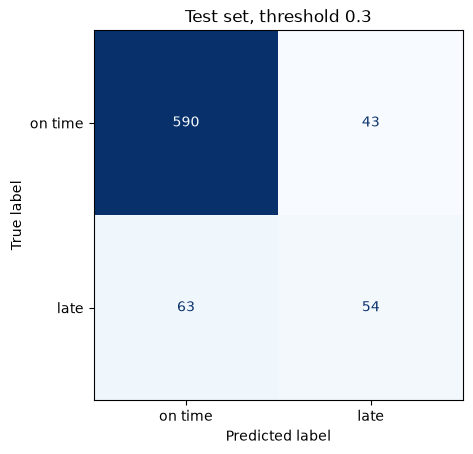

{'precision': 0.557, 'recall': 0.462, 'f1': 0.505, 'roc_auc': 0.822}


In [8]:
metrics = json.loads((ROOT / "reports" / "metrics.json").read_text())
cm = metrics["confusion_matrix"]
matrix = np.array(
    [
        [cm["true_negative"], cm["false_positive"]],
        [cm["false_negative"], cm["true_positive"]],
    ]
)
display = ConfusionMatrixDisplay(matrix, display_labels=["on time", "late"])
display.plot(cmap="Blues", colorbar=False)
plt.title(f"Test set, threshold {metrics['threshold']}")
plt.show()
print({k: metrics[k] for k in ["precision", "recall", "f1", "roc_auc"]})

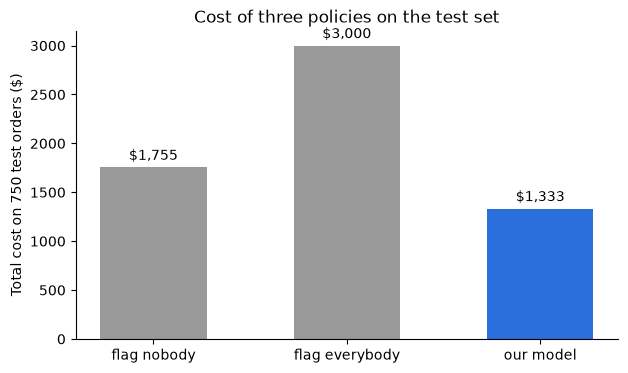

Saving against today's policy: $422 (24%)


In [9]:
policies = metrics["policy_costs"]
labels = ["flag nobody", "flag everybody", "our model"]
values = [policies["flag_nobody"], policies["flag_everybody"], policies["model"]]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(labels, values, color=["#999999", "#999999", "#2a6fdb"], width=0.55)
ax.bar_label(bars, labels=[f"${v:,}" for v in values], padding=3)
ax.set_ylabel(f"Total cost on {metrics['test_orders']} test orders ($)")
ax.set_title("Cost of three policies on the test set")
ax.spines[["top", "right"]].set_visible(False)
plt.show()
saving = policies["flag_nobody"] - policies["model"]
share = saving / policies["flag_nobody"]
print(f"Saving against today's policy: ${saving:,} ({share:.0%})")

## 8. Recommendation

**Would I use this model?** Yes, as a trial. On 750 orders it has never seen, it cuts the cost of lateness
from $1,755 (flag nobody, today's policy) to $1,333, a saving of about 24%, and it beats flagging everybody
($3,000) by a wide margin.

**Why this threshold?** 0.30 gave the lowest total cost on out-of-fold predictions from the training data.
A missed late order costs $15 and a voucher $4, so it pays to flag an order well before it is more likely
late than not.

**What did I exclude and why?** `customer_rating`, because it is given after delivery and leaks the answer
(ROC-AUC jumps from 0.82 to 0.92 with it); `order_id`, a label with no meaning; and the raw `hour`, replaced by
a rush-hour flag that scored better.

**One limitation.** The data is invented and its effects add up neatly, so a simple model wins here. Real
deliveries depend on things this table lacks, such as city area and live traffic, and the saving should be
confirmed in a small live trial before the voucher is offered to every customer.